<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Haybarn](https://query.farm/products/haybarn/) · [Guide](README.md)

# 03 · How much of the next funding payment is still undecided?

A precise-looking funding estimate does not tell us how much of the settlement
window has been observed. Does half the elapsed time mean half the payment is
already determined? Inspect the premium input, compare elapsed time with accrued
weight, and change the assumption about the remainder.

Replay begins with a real recorded minute, then uses **synthetic full-window test
premiums** to demonstrate the nowcast. Live mode queries the current window. The
source labels, calculations and numerical conclusions follow the mode you select.

## Choose the run

`ASSUMED_PREMIUM_BPS` sets the remaining premium in **basis points**; SQL converts
it to the decimal fraction accepted by the worker. Comparison scenarios always
include that selected value. Replay supports `KXBTCPERP`; its raw-premium dates can
be narrowed within **13 Nov 2026 01:00 → 01:01 UTC**. Live mode accepts another
supported Kalshi symbol and defaults to the most recent complete minute. These
dates affect the opening premium plot; the nowcast uses the worker's current window.

Edit the visible parameters, then **Restart Kernel → Run All**. Saved outputs are a replay run.
`DATA_MODE = "live"` uses public APIs with recent default dates; there is no fallback to fixtures.
[Setup instructions](README.md#run-in-vs-code) are separate from the analysis.

The visible connection SQL downloads the pinned **v0.1.5** worker through `uvx`. No local worker build or path configuration is needed. The selected data mode configures its fixture and clock environment before connection.


In [1]:
DATA_MODE = "replay"
SYMBOL = "KXBTCPERP"
START_DATE = None              # Raw-premium start, inclusive UTC
END_DATE = None                # Raw-premium end, exclusive UTC
ASSUMED_PREMIUM_BPS = 2.0
COMPARISON_PREMIUM_BPS = (-2.0, 0.5, 10.0)

In [2]:
# Python setup · expand to inspect environment and shared presentation helpers.
from pathlib import Path
import os
import sys
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file() and (p / "fixtures/venues").is_dir()
)
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from notebook_support import (
    ASK, BID, COLORS, VENUE_NAMES, finite_numbers, finish_chart, make_run,
    money, number, prose, require_rows, set_theme, sql_text,
)
run = make_run(DATA_MODE, NOTEBOOK_DIR)
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

def chart(fig, title, subtitle, source=None):
    finish_chart(fig, title, subtitle, source or run.source)

Tip: You may define configurations in /Users/rusty/Development/vgi-perps/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-perps/notebooks/pyproject.toml.

In [3]:
symbol = SYMBOL.strip().upper()
if not symbol or (run.replay and symbol != "KXBTCPERP"):
    raise ValueError("Replay supports SYMBOL='KXBTCPERP'; live mode requires a supported Kalshi symbol.")
assumed_bps = finite_numbers([ASSUMED_PREMIUM_BPS], "ASSUMED_PREMIUM_BPS")[0]
comparison_bps = finite_numbers([assumed_bps, *COMPARISON_PREMIUM_BPS], "comparison premiums")
premium_window = run.window("premium", START_DATE, END_DATE)
run.badge(raw_premiums=premium_window)
nowcast_source = ("Synthetic full-window premiums · fixed replay clock · VGI / Query Farm" if run.replay else run.source)
prose(f"Remaining-premium assumption: **{assumed_bps:+g} bps**. " +
      ("**Full-window nowcast inputs are synthetic.** The opening minute is a separate real recording."
       if run.replay else "Full-window nowcast inputs come from live public APIs; repeated calls may see revised observations."))

**REPLAY · local recorded responses**  
Recorded worker clock: **2026-11-13 01:20:00 UTC**. Venue requests stay local.  
**Raw Premiums:** 13 Nov 2026 01:00 → 13 Nov 2026 01:01 UTC (end excluded)

Remaining-premium assumption: **+2 bps**. **Full-window nowcast inputs are synthetic.** The opening minute is a separate real recording.

In [4]:
%%sql
-- uvx fetches the pinned worker release; no local worker installation is needed.
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'perps' (TYPE vgi, LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-perps@v0.1.5 vgi-perps-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Begin with the premium that feeds the calculation

`raw_kalshi_premium_index()` exposes the ingredient before we interpret a funding
estimate. Premiums are signed fractions internally; multiplying by 10,000 expresses
them in basis points. Keep the range and time coverage beside the line. One observed
second cannot stand in for an entire settlement window.

In [5]:
%%sql premiums <<
CREATE OR REPLACE TABLE source_premiums AS
SELECT * FROM perps.main.raw_kalshi_premium_index({{ sql_text(symbol) }},
    start_date := TIMESTAMPTZ {{ sql_text(premium_window.fetch_start) }},
    end_date := TIMESTAMPTZ {{ sql_text(premium_window.fetch_end) }});
SELECT ts, premium_bps FROM source_premiums
WHERE ts >= TIMESTAMPTZ {{ sql_text(premium_window.start) }}
  AND ts < TIMESTAMPTZ {{ sql_text(premium_window.end) }} ORDER BY ts;

findfont: Failed to find font weight semibold for Arial, now using 700.


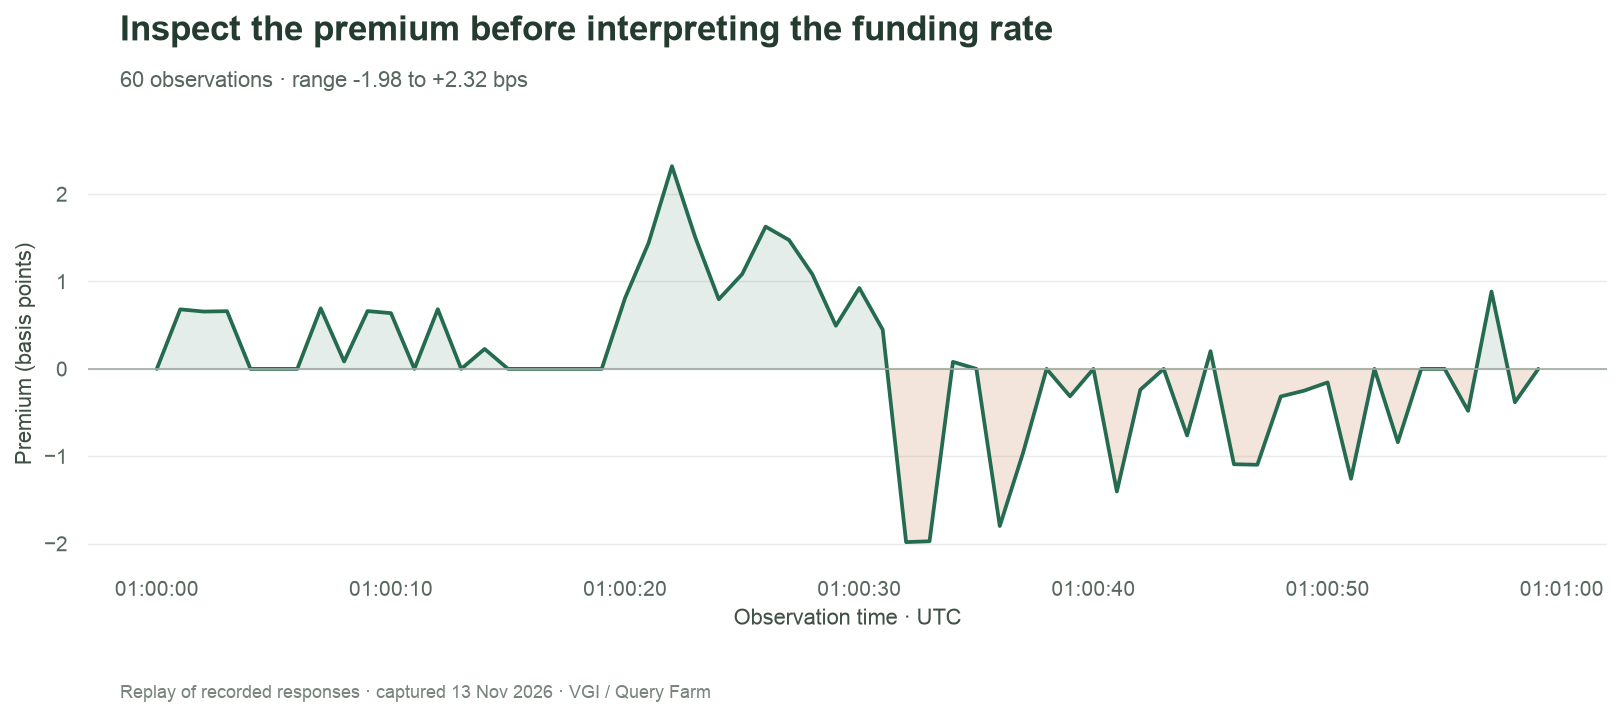

In [6]:
if premiums.empty:
    prose("No premiums returned for the selected interval. The opening chart is unavailable; the full-window nowcast is a separate request.")
else:
    fig, ax = plt.subplots(figsize=(11, 4.7))
    ax.plot(premiums.ts, premiums.premium_bps, color=COLORS["kalshi"], linewidth=1.8)
    ax.fill_between(premiums.ts, premiums.premium_bps, 0, where=premiums.premium_bps>=0,
                    interpolate=True, color=BID, alpha=0.12)
    ax.fill_between(premiums.ts, premiums.premium_bps, 0, where=premiums.premium_bps<0,
                    interpolate=True, color=ASK, alpha=0.18)
    ax.axhline(0, color="#A0ACA4", linewidth=0.8)
    ax.set(ylabel="Premium (basis points)", xlabel="Observation time · UTC")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz="UTC"))
    ax.grid(axis="x", visible=False)
    chart(fig, "Inspect the premium before interpreting the funding rate",
          f"{len(premiums)} observations · range {premiums.premium_bps.min():+.2f} to {premiums.premium_bps.max():+.2f} bps")

In [7]:
if not premiums.empty:
    prose(f"The selected interval returns **{len(premiums)} observations**, from **{premiums.ts.min()}** to **{premiums.ts.max()}**. "
          f"Premium ranges from **{premiums.premium_bps.min():+.2f} to {premiums.premium_bps.max():+.2f} bps**. "
          "The averaging rule and the window determine how these ingredients become a funding estimate.")

The selected interval returns **60 observations**, from **2026-11-13 01:00:00+00:00** to **2026-11-13 01:00:59+00:00**. Premium ranges from **-1.98 to +2.32 bps**. The averaging rule and the window determine how these ingredients become a funding estimate.

## Freeze the clock and separate observation from assumption

`kalshi_funding_nowcast()` reports the weighted average observed so far and a
projection that fills the rest of the window with your assumed premium. Keep the
window, `as_of`, elapsed seconds and missing-premium rule beside the rate.

The worker clock is fixed at the start of this run. In replay, the full-window
premiums are synthetic fixtures with missing seconds; they are separate from the
opening recorded minute and cannot be validated against a published venue estimate
from different inputs. In live mode, the clock stays fixed but API responses can
still be updated between calls.

In [8]:
%%sql checkpoint <<
CREATE OR REPLACE TABLE nowcast AS
SELECT * FROM perps.main.kalshi_funding_nowcast({{ sql_text(symbol) }},
    assume_premium := {{ assumed_bps / 10000 }});
SELECT symbol, window_start, as_of, funding_time, interval_hours, elapsed_seconds,
       weight_accrued, accrued_rate * 10000 AS accrued_bps,
       assumed_premium * 10000 AS assumed_remaining_bps,
       projected_rate_raw * 10000 AS raw_bps, projected_rate * 10000 AS settlement_bps,
       funding_deadband * 10000 AS deadband_bps, funding_cap * 10000 AS cap_bps,
       invalid_premium_handling
FROM nowcast;

In [9]:
display(checkpoint)
require_rows(checkpoint, "nowcast")
point = checkpoint.iloc[0]
total_seconds = int(point.interval_hours*3600)
clock_pct = 100*point.elapsed_seconds/total_seconds
weight_pct = 100*point.weight_accrued
prose(f"At **{point.as_of}**, **{clock_pct:.1f}% of the clock time** has passed, but "
      f"**{weight_pct:.1f}% of the funding weight** has accrued. **{100-weight_pct:.1f}%** remains. "
      f"Assuming **{assumed_bps:+g} bps** for the remainder gives a raw **{number(point.raw_bps, 4)} bps** "
      f"and a settlement projection of **{number(point.settlement_bps, 4)} bps**. "
      f"The missing-premium rule is **{point.invalid_premium_handling}**.")
assert 0 <= point.weight_accrued <= 1
assert abs(point.weight_accrued - point.elapsed_seconds*(point.elapsed_seconds+1)/(total_seconds*(total_seconds+1))) < 1e-12

,symbol,window_start,as_of,funding_time,interval_hours,elapsed_seconds,weight_accrued,accrued_bps,assumed_remaining_bps,raw_bps,settlement_bps,deadband_bps,cap_bps,invalid_premium_handling
0,KXBTCPERP,2026-11-12 21:00:00+00:00,2026-11-13 01:20:00+00:00,2026-11-13 05:00:00+00:00,8.0,15600,0.29341,0.00044,2.0,1.41331,1.41331,1.0,200.0,dampen


At **2026-11-13 01:20:00+00:00**, **54.2% of the clock time** has passed, but **29.3% of the funding weight** has accrued. **70.7%** remains. Assuming **+2 bps** for the remainder gives a raw **1.4133 bps** and a settlement projection of **1.4133 bps**. The missing-premium rule is **dampen**.

## Compare the clock with cumulative funding weight

Second `i` carries weight `i`. Consequently, cumulative weight is
`t × (t + 1) / (T × (T + 1))`, where `t` is elapsed seconds and `T` is the interval
length returned by the worker. Later seconds carry more influence. The SQL traces
both curves through the actual interval rather than assuming a fixed duration.

In [10]:
%%sql weights <<
WITH grid AS (
    SELECT i * {{ total_seconds }} / 100.0 AS second FROM range(0, 101) AS t(i)
)
SELECT second / 3600 AS hours_elapsed,
       second / {{ total_seconds }} AS time_fraction,
       second * (second + 1) / ({{ total_seconds }}::DOUBLE * ({{ total_seconds }} + 1)) AS weight_fraction
FROM grid ORDER BY second;

findfont: Failed to find font weight semibold for Arial, now using 700.


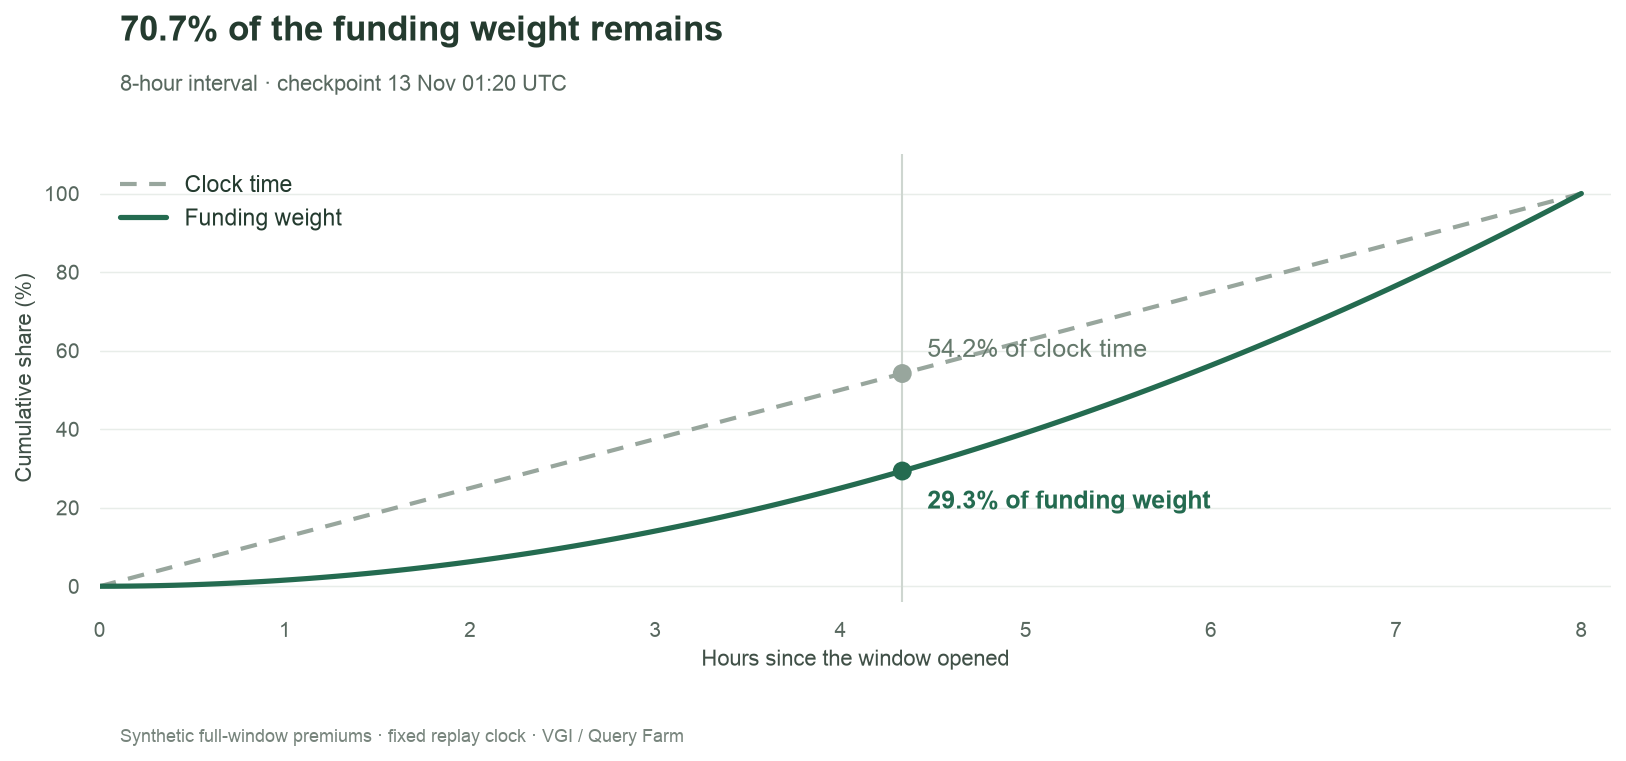

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(weights.hours_elapsed, weights.time_fraction*100, linestyle=(0,(4,3)), color="#98A69D", label="Clock time")
ax.plot(weights.hours_elapsed, weights.weight_fraction*100, color=BID, linewidth=2.5, label="Funding weight")
x = point.elapsed_seconds/3600
ax.axvline(x, color="#CED6D0", linewidth=1)
ax.scatter([x,x], [weight_pct,clock_pct], color=[BID,"#98A69D"], s=65,zorder=4)
align, offset = ("right", -12) if x > point.interval_hours*0.6 else ("left", 12)
ax.annotate(f"{weight_pct:.1f}% of funding weight", (x,weight_pct), xytext=(offset,-18),
            textcoords="offset points", ha=align, color=BID, fontweight="semibold")
ax.annotate(f"{clock_pct:.1f}% of clock time", (x,clock_pct), xytext=(offset,8),
            textcoords="offset points", ha=align, color="#65796C")
ax.set(xlabel="Hours since the window opened", ylabel="Cumulative share (%)",
       xlim=(0,point.interval_hours*1.02), ylim=(-4,110))
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
chart(fig, f"{100-weight_pct:.1f}% of the funding weight remains",
      f"{point.interval_hours:g}-hour interval · checkpoint {point.as_of:%d %b %H:%M UTC}", nowcast_source)

## Change the remaining premium

The next worker calls vary `assume_premium`, including your selected value.
SQL makes the bps-to-fraction conversion explicit. The worker applies its own
weighting, deadband and cap. Replay isolates the assumption using identical recorded
inputs; live calls can also reflect revisions to the observed data.

In [12]:
%%sql scenarios <<
CREATE OR REPLACE TABLE worker_scenarios AS
{% for bps in comparison_bps %}
SELECT * FROM perps.main.kalshi_funding_nowcast({{ sql_text(symbol) }},
    assume_premium := {{ bps / 10000 }})
{% if not loop.last %}UNION ALL{% endif %}
{% endfor %};
SELECT assumed_premium * 10000 AS assumed_bps,
       projected_rate_raw * 10000 AS raw_bps, projected_rate * 10000 AS settlement_bps,
       projected_rate_annualized * 100 AS simple_annualized_pct
FROM worker_scenarios ORDER BY assumed_premium;

In [13]:
display(scenarios)
zero = scenarios[scenarios.settlement_bps.eq(0)]
prose(f"Of the **{len(scenarios)} scenarios**, **{len(zero)} settle at zero** after the worker applies its rules. " +
      ("Their remaining-premium assumptions are " + ", ".join(f"**{v:+g} bps**" for v in zero.assumed_bps) + ". " if not zero.empty else "") +
      "These are conditional projections. Annualization is a simple unit conversion, not a promised return.")
dampen = point.invalid_premium_handling == "dampen"
prose(f"The reported deadband is **{number(point.deadband_bps, 3)} bps**; the cap is **{number(point.cap_bps, 3)} bps**. " +
      ("The following local calculation explains the dampen rule."
       if dampen else "The venue reports a different missing-premium rule. The dampen-only curve and agreement check below are explicitly omitted; worker scenarios remain valid."))

,assumed_bps,raw_bps,settlement_bps,simple_annualized_pct
0,-2.0,-1.41305,-1.41305,-15.47286
1,0.5,0.35342,0.00000,0.00000
2,2.0,1.41331,1.41331,15.47572
3,10.0,7.06602,7.06602,77.37288


Of the **4 scenarios**, **1 settle at zero** after the worker applies its rules. Their remaining-premium assumptions are **+0.5 bps**. These are conditional projections. Annualization is a simple unit conversion, not a promised return.

The reported deadband is **1.000 bps**; the cap is **200.000 bps**. The following local calculation explains the dampen rule.

## Look for the thresholds, not just the slope

Under `dampen`, the raw projection is
`accrued_rate × weight_accrued + assumed_premium × (1 − weight_accrued)`.
A raw value strictly inside the deadband becomes zero; the cap limits the remainder.
The following SQL sweeps that formula locally from one materialized worker result.
It handles absent thresholds and emits no curve for another missing-premium rule.

The left panel extends the assumptions to show the cap; the right panel focuses
on the deadband and the selected scenarios. Dots are actual worker calls. In live
mode a dot can differ from the curve if its observed inputs were revised.

In [14]:
cap_bps = float(point.cap_bps) if pd.notna(point.cap_bps) else None
deadband_bps = float(point.deadband_bps) if pd.notna(point.deadband_bps) else 0.0
remaining = max(1-point.weight_accrued, 1e-6)
zoom_span = max(4.0, 3*deadband_bps/remaining, *(abs(v)*1.2 for v in comparison_bps))
wide_span = max(zoom_span*2, (cap_bps or 200)*1.5/remaining)

In [15]:
%%sql sensitivity <<
WITH assumptions AS (
    SELECT i * {{ wide_span }} / 1000.0 / 10000 AS assumed_premium FROM range(-1000, 1001) AS r(i)
    UNION
    SELECT i * {{ zoom_span }} / 1000.0 / 10000 AS assumed_premium FROM range(-1000, 1001) AS r(i)
), raw AS (
    SELECT a.assumed_premium, n.funding_deadband, n.funding_cap,
           coalesce(n.accrued_rate, 0) * n.weight_accrued
           + a.assumed_premium * (1-n.weight_accrued) AS raw_rate
    FROM nowcast n CROSS JOIN assumptions a WHERE n.invalid_premium_handling = 'dampen'
)
SELECT assumed_premium * 10000 AS assumed_bps, raw_rate * 10000 AS raw_bps,
       10000 * CASE WHEN abs(raw_rate) < coalesce(funding_deadband, 0) THEN 0
                   WHEN funding_cap IS NULL THEN raw_rate
                   ELSE greatest(-funding_cap, least(funding_cap, raw_rate)) END AS settlement_bps
FROM raw ORDER BY assumed_premium;

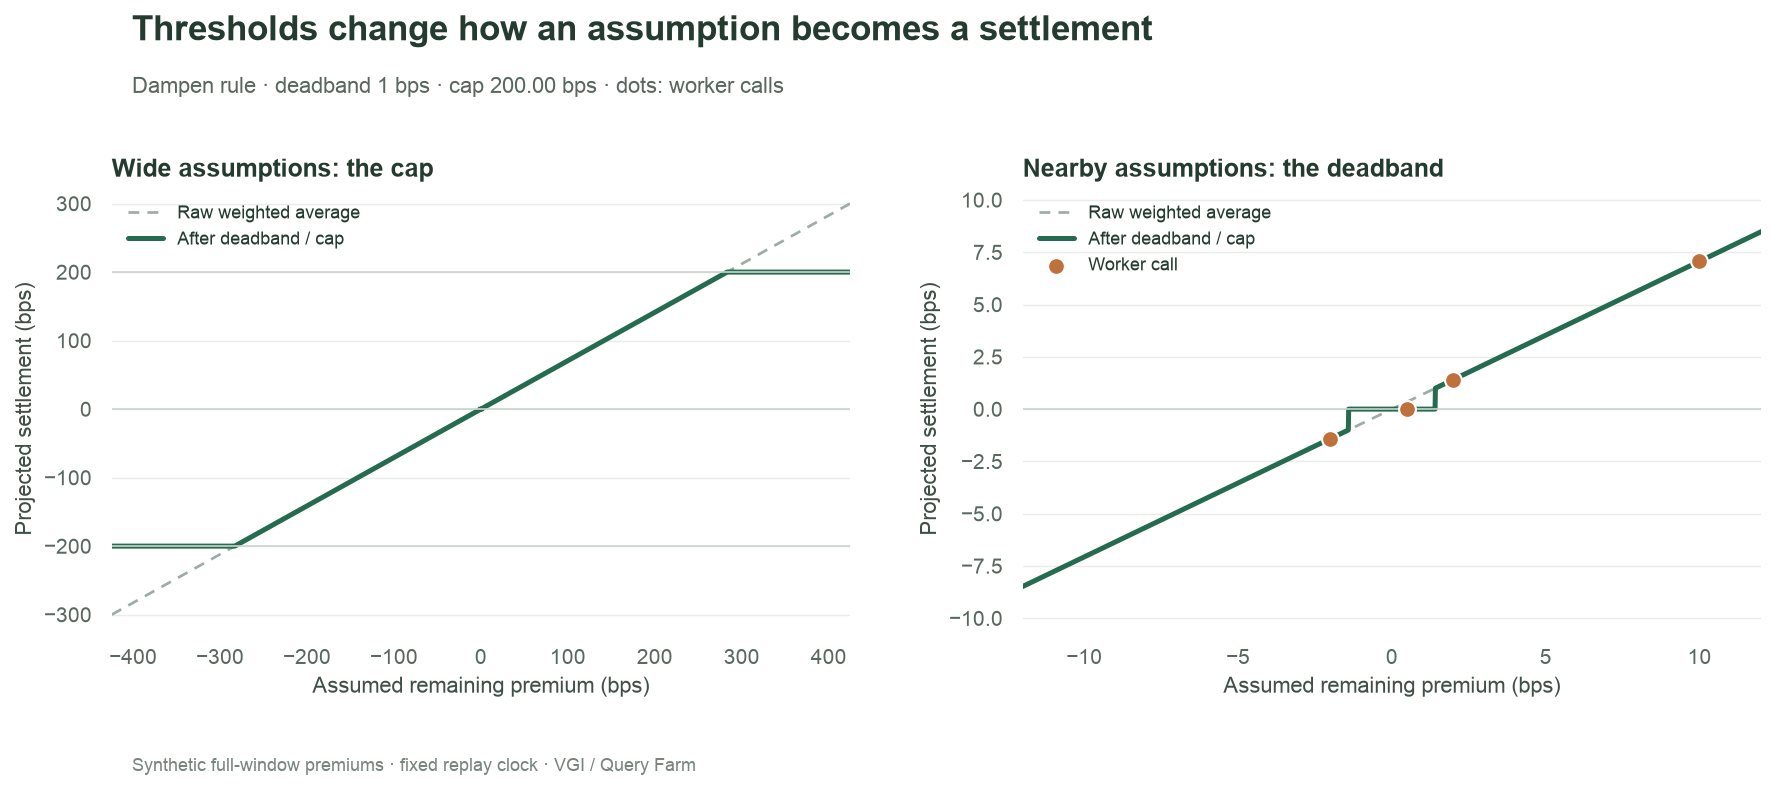

In [16]:
if not sensitivity.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
    for ax in axes:
        ax.plot(sensitivity.assumed_bps, sensitivity.raw_bps, linestyle=(0,(4,3)), color="#9EACA3", linewidth=1.3, label="Raw weighted average")
        ax.plot(sensitivity.assumed_bps, sensitivity.settlement_bps, color=BID, linewidth=2.4, label="After deadband / cap")
        ax.axhline(0, color="#CAD4CC", linewidth=0.8)
        ax.set(xlabel="Assumed remaining premium (bps)", ylabel="Projected settlement (bps)")
        ax.grid(axis="x", visible=False)
    if cap_bps is not None:
        for boundary in (-cap_bps, cap_bps):
            axes[0].axhline(boundary, color="#CAD4CC", linewidth=0.8)
        axes[0].set_ylim(-cap_bps*1.6-1, cap_bps*1.6+1)
    axes[0].set(title="Wide assumptions: the cap", xlim=(-wide_span,wide_span))
    axes[1].scatter(scenarios.assumed_bps, scenarios.settlement_bps, color=ASK, s=65, edgecolor="white", zorder=4, label="Worker call")
    local = sensitivity[sensitivity.assumed_bps.between(-zoom_span,zoom_span)]
    lower = min(local.settlement_bps.min(), scenarios.settlement_bps.min())
    upper = max(local.settlement_bps.max(), scenarios.settlement_bps.max())
    pad = max((upper-lower)*0.12, 0.5)
    axes[1].set(title="Nearby assumptions: the deadband", xlim=(-zoom_span,zoom_span), ylim=(lower-pad,upper+pad))
    axes[0].legend(loc="upper left", fontsize=8.5); axes[1].legend(loc="upper left", fontsize=8.5)
    chart(fig, "Thresholds change how an assumption becomes a settlement",
          f"Dampen rule · deadband {deadband_bps:g} bps · cap {number(cap_bps)} bps · dots: worker calls", nowcast_source)

### Check the explanation against the worker

Recompute each supported scenario from **its own** observed inputs. This tests the
explanation even if live responses change between calls. The tolerance is `1e-12`
in fractional-rate units; scenario counts follow the selected parameters. A changed
missing-premium rule is reported explicitly rather than treated as agreement.

In [17]:
%%sql agreement <<
WITH raw AS (
    SELECT *, coalesce(accrued_rate, 0) * weight_accrued
              + coalesce(assumed_premium, 0) * (1-weight_accrued) AS raw_rate
    FROM worker_scenarios WHERE invalid_premium_handling = 'dampen'
), checked AS (
    SELECT *, CASE WHEN abs(raw_rate) < coalesce(funding_deadband, 0) THEN 0
                   WHEN funding_cap IS NULL THEN raw_rate
                   ELSE greatest(-funding_cap, least(funding_cap, raw_rate)) END AS sql_rate
    FROM raw
)
SELECT count(*) AS scenarios_checked,
       max(abs(sql_rate - projected_rate)) AS max_absolute_error,
       bool_and(projected_rate IS NOT NULL AND abs(sql_rate-projected_rate) < 1e-12) AS agrees_with_worker
FROM checked;

In [18]:
display(agreement)
check = agreement.iloc[0]
if check.scenarios_checked:
    assert bool(check.agrees_with_worker), "Local formula differs from the worker; inspect the rule and inputs."
    prose(f"**{int(check.scenarios_checked)} of {len(scenarios)} scenarios checked**, with maximum absolute difference "
          f"**{check.max_absolute_error:.2g}** in fractional-rate units. The arithmetic supports the explanation, not the assumption's predictive accuracy.")
else:
    prose("No dampen scenarios were available. The local arithmetic check was omitted.")

,scenarios_checked,max_absolute_error,agrees_with_worker
0,4,1.08420e-19,True


**4 of 4 scenarios checked**, with maximum absolute difference **1.1e-19** in fractional-rate units. The arithmetic supports the explanation, not the assumption's predictive accuracy.

## Experiment: can a positive assumption still settle at zero?

Set `ASSUMED_PREMIUM_BPS = 1.0`, leaving the other parameters unchanged.
**Predict first:** combine the current accrued component with that remaining premium,
then compare the raw projection with the returned deadband. Restart and run all.
**Inspect:** the selected-rate callout, worker scenario table and deadband panel.

A positive premium can still produce zero settlement if the weighted projection
falls inside the deadband. The result depends on the checkpoint and observed inputs;
it is not guaranteed in live mode. Restore `ASSUMED_PREMIUM_BPS = 2.0` afterward.
The useful reading of a nowcast keeps the observation, remaining weight, assumption
and settlement rules together.

[All notebooks](README.md) · [SQL reference](https://github.com/Query-farm/vgi-perps#sql-surface) ·
[Venue mappings](https://github.com/Query-farm/vgi-perps/blob/main/docs/VENUES.md) · [Notebook standard](STANDARD.md)

The final collapsed cell releases this run's connection. Restart and run from the top after editing parameters.

In [19]:
# Cleanup · release the connection and worker
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>